# 01 — Sorghum Dataset Exploration

**Dataset:** Sorghum-100 Cultivar Identification – FGVC 9  
**Date:** August 14, 2026  
**Purpose:** Understand and document the raw training dataset before any sampling or splitting decisions.

---

### Actual dataset layout (discovered August 14)

The dataset is **flat** — images and CSVs live directly inside `Dataset/`, not under a `Sorghum/` subfolder.

```
Dataset/
├── <image files>.png          # training images (flat, no subfolder)
├── train_cultivar_mapping.csv
├── germplasm.csv
└── season_6_aboveground_fresh_biomass_manual.csv
```


## Section 1 — Imports

In [1]:
from pathlib import Path
import random
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## Section 2 — Configuration

In [2]:
# ── Configure this path to point at your local Dataset/ folder ──────────────
# The dataset is flat: images and CSVs are directly inside DATASET_ROOT.
# Do NOT hard-code a personal Windows path here.
DATASET_ROOT = Path("../../Dataset")   # adjust relative to notebooks/ if needed
# ─────────────────────────────────────────────────────────────────────────────

MAPPING_CSV  = DATASET_ROOT / "train_cultivar_mapping.csv"
GERMPLASM_CSV = DATASET_ROOT / "germplasm.csv"
BIOMASS_CSV  = DATASET_ROOT / "season_6_aboveground_fresh_biomass_manual.csv"

RESULTS_DIR  = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_SEED  = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

## Section 3 — Dataset path verification

In [3]:
paths_to_check = {
    "Dataset root":    DATASET_ROOT,
    "Mapping CSV":     MAPPING_CSV,
    "Germplasm CSV":   GERMPLASM_CSV,
    "Biomass CSV":     BIOMASS_CSV,
}

all_ok = True
for label, p in paths_to_check.items():
    status = "OK" if p.exists() else "MISSING"
    if status == "MISSING":
        all_ok = False
    print(f"{status:8s}  {label}: {p}")

if not all_ok:
    print("\n⚠  One or more paths are missing. Update DATASET_ROOT above before continuing.")

OK        Dataset root: ..\..\Dataset
OK        Mapping CSV: ..\..\Dataset\train_cultivar_mapping.csv
OK        Germplasm CSV: ..\..\Dataset\germplasm.csv
OK        Biomass CSV: ..\..\Dataset\season_6_aboveground_fresh_biomass_manual.csv


## Section 4 — Count images on disk

In [4]:
# Images are flat inside DATASET_ROOT (no train_images/ subfolder)
image_files = sorted(DATASET_ROOT.glob("*.png"))
print(f"PNG images found in {DATASET_ROOT}: {len(image_files)}")

if len(image_files) == 0:
    print("⚠  No images found. Verify DATASET_ROOT is correct.")

PNG images found in ..\..\Dataset: 5000


## Section 5 — Load and inspect train_cultivar_mapping.csv

In [5]:
df = pd.read_csv(MAPPING_CSV)
print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Shape: (22194, 2)

Column names: ['image', 'cultivar']

Data types:
image       object
cultivar    object
dtype: object


In [6]:
print("First 5 rows:")
df.head()

First 5 rows:


,image,cultivar
0,2017-06-16__12-24-20-930.png,PI_257599
1,2017-06-02__16-48-57-866.png,PI_154987
2,2017-06-12__13-18-07-707.png,PI_92270
3,2017-06-22__13-18-06-841.png,PI_152651
4,2017-06-26__12-56-48-642.png,PI_176766


In [7]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,image,cultivar
22189,2017-06-16__12-27-16-266.png,PI_170787
22190,2017-06-28__11-19-57-454.png,PI_156393
22191,2017-06-28__10-20-32-417.png,PI_152923
22192,2017-06-28__12-47-02-714.png,PI_257599
22193,2017-06-04__13-12-56-053.png,PI_196586


In [8]:
# Confirmed column names from inspection: 'image' and 'cultivar'
IMAGE_COL   = "image"
CULTIVAR_COL = "cultivar"

print(f"Image filename column : '{IMAGE_COL}'")
print(f"Cultivar label column : '{CULTIVAR_COL}'")

Image filename column : 'image'
Cultivar label column : 'cultivar'


## Section 6 — Basic dataset statistics

In [9]:
total_rows        = len(df)
unique_images     = df[IMAGE_COL].nunique()
unique_cultivars  = df[CULTIVAR_COL].nunique()
counts_per_class  = df[CULTIVAR_COL].value_counts()

print(f"Total rows in CSV          : {total_rows}")
print(f"Unique image filenames     : {unique_images}")
print(f"Unique cultivar labels     : {unique_cultivars}")
print(f"\nImages per cultivar:")
print(f"  Min    : {counts_per_class.min()}")
print(f"  Max    : {counts_per_class.max()}")
print(f"  Mean   : {counts_per_class.mean():.1f}")
print(f"  Median : {counts_per_class.median():.1f}")

Total rows in CSV          : 22194
Unique image filenames     : 22194
Unique cultivar labels     : 100

Images per cultivar:
  Min    : 134
  Max    : 298
  Mean   : 221.9
  Median : 235.5


In [10]:
# Summary table: cultivar → image count
summary_table = counts_per_class.reset_index()
summary_table.columns = ["cultivar", "image_count"]
print(summary_table.to_string(index=False))

 cultivar  image_count
PI_156393          298
PI_155760          282
PI_157030          272
PI_329299          269
PI_152771          262
 PI_52606          258
PI_152727          255
 PI_22913          255
PI_152751          252
PI_154844          251
PI_154988          251
PI_176766          249
PI_180348          249
PI_156326          248
PI_156487          248
PI_153877          248
PI_329338          247
PI_266927          246
PI_154987          246
PI_156330          245
PI_297171          244
PI_170787          244
PI_329286          244
PI_253986          244
PI_152828          242
PI_175919          242
PI_156268          241
PI_152862          241
PI_145633          240
PI_329300          240
PI_329326          240
PI_155516          240
PI_276837          239
PI_329301          239
PI_329351          239
PI_329319          239
PI_303658          239
PI_152651          238
PI_229841          238
PI_302252          238
PI_152967          237
PI_156217          237
PI_154944  

## Section 7 — Cultivar distribution chart

Saved: ..\results\cultivar_distribution.png


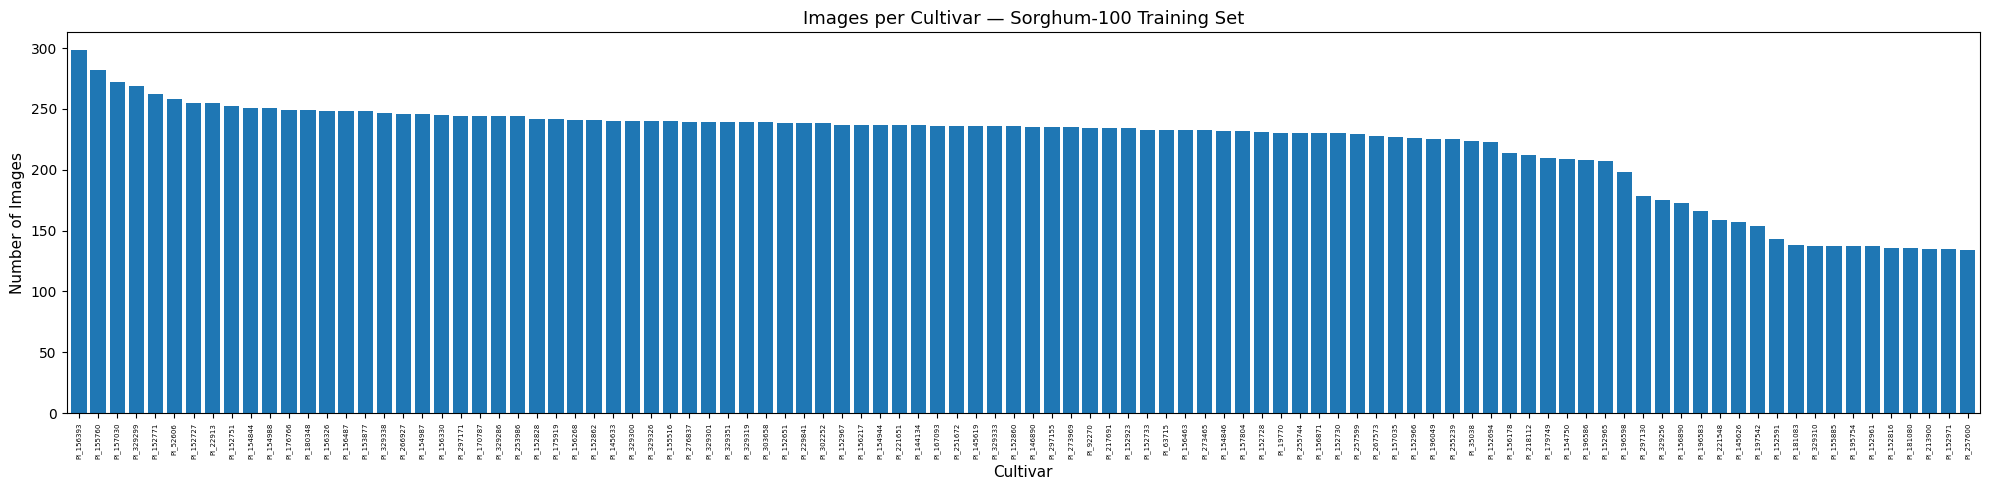

In [11]:
fig, ax = plt.subplots(figsize=(20, 5))
counts_per_class.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Images per Cultivar — Sorghum-100 Training Set", fontsize=13)
ax.set_xlabel("Cultivar", fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)
ax.tick_params(axis="x", labelsize=5, rotation=90)
plt.tight_layout()

out_path = RESULTS_DIR / "cultivar_distribution.png"
fig.savefig(out_path, dpi=150)
print(f"Saved: {out_path}")
plt.show()

## Section 8 — Missing values and duplicates

In [12]:
print("Missing values per column:")
print(df.isnull().sum())

missing_image    = df[IMAGE_COL].isnull().sum()
missing_cultivar = df[CULTIVAR_COL].isnull().sum()
print(f"\nRows with missing image filename : {missing_image}")
print(f"Rows with missing cultivar label : {missing_cultivar}")

if missing_cultivar > 0:
    print("\nSample rows with missing cultivar:")
    print(df[df[CULTIVAR_COL].isnull()].head(10).to_string())

Missing values per column:
image       0
cultivar    1
dtype: int64

Rows with missing image filename : 0
Rows with missing cultivar label : 1

Sample rows with missing cultivar:
          image cultivar
3329  .DS_Store      NaN


In [13]:
dup_rows     = df.duplicated().sum()
dup_images   = df[IMAGE_COL].duplicated().sum()

print(f"Fully duplicate rows          : {dup_rows}")
print(f"Duplicate image filenames     : {dup_images}")

if dup_images > 0:
    print("\nSample duplicate image entries:")
    dup_mask = df[IMAGE_COL].duplicated(keep=False)
    print(df[dup_mask].sort_values(IMAGE_COL).head(10).to_string())

Fully duplicate rows          : 0
Duplicate image filenames     : 0


## Section 9 — Verify images exist on disk

In [14]:
# Build a set of filenames present on disk for fast lookup
disk_filenames = {p.name for p in image_files}

# Check each mapped filename
mapped_filenames = df[IMAGE_COL].dropna().tolist()
missing_on_disk  = [f for f in mapped_filenames if f not in disk_filenames]
unmapped_on_disk = [f for f in disk_filenames  if f not in set(mapped_filenames)]

print(f"Mapped filenames in CSV              : {len(mapped_filenames)}")
print(f"Mapped files MISSING on disk         : {len(missing_on_disk)}")
print(f"Files on disk NOT in mapping CSV     : {len(unmapped_on_disk)}")

if missing_on_disk:
    print("\nSample missing files:")
    for f in missing_on_disk[:10]:
        print(" ", f)

if unmapped_on_disk:
    print("\nSample unmapped files on disk:")
    for f in list(unmapped_on_disk)[:10]:
        print(" ", f)

Mapped filenames in CSV              : 22194
Mapped files MISSING on disk         : 17194
Files on disk NOT in mapping CSV     : 0

Sample missing files:
  2017-06-23__16-27-06-445.png
  .DS_Store
  2017-06-13__11-35-44-977.png
  2017-06-13__11-38-22-362.png
  2017-06-14__13-38-32-490.png
  2017-06-28__10-29-01-256.png
  2017-06-29__12-07-47-748.png
  2017-06-15__12-45-48-297.png
  2017-06-27__11-16-21-663.png
  2017-06-27__13-10-52-699.png


## Section 10 — Image properties (sampled)

In [15]:
SAMPLE_SIZE = min(100, len(image_files))
sample_paths = random.sample(image_files, SAMPLE_SIZE)

widths, heights, modes, formats = [], [], [], []

for p in sample_paths:
    with Image.open(p) as img:
        w, h = img.size
        widths.append(w)
        heights.append(h)
        modes.append(img.mode)
        formats.append(img.format)

print(f"Sample size: {SAMPLE_SIZE} images")
print(f"\nWidth  — min: {min(widths)}, max: {max(widths)}, mean: {sum(widths)/len(widths):.0f}")
print(f"Height — min: {min(heights)}, max: {max(heights)}, mean: {sum(heights)/len(heights):.0f}")
print(f"\nUnique color modes   : {set(modes)}")
print(f"Unique image formats : {set(formats)}")

unique_sizes = set(zip(widths, heights))
print(f"\nUnique (width, height) combinations: {len(unique_sizes)}")
if len(unique_sizes) <= 5:
    print("Sizes:", unique_sizes)
else:
    print("Dimensions are NOT uniform across the sample.")

Sample size: 100 images

Width  — min: 1024, max: 1024, mean: 1024
Height — min: 1024, max: 1024, mean: 1024

Unique color modes   : {'RGB'}
Unique image formats : {'PNG'}

Unique (width, height) combinations: 1
Sizes: {(1024, 1024)}


## Section 11 — Visual inspection (sample grid)

Saved: ..\results\sample_training_images.png


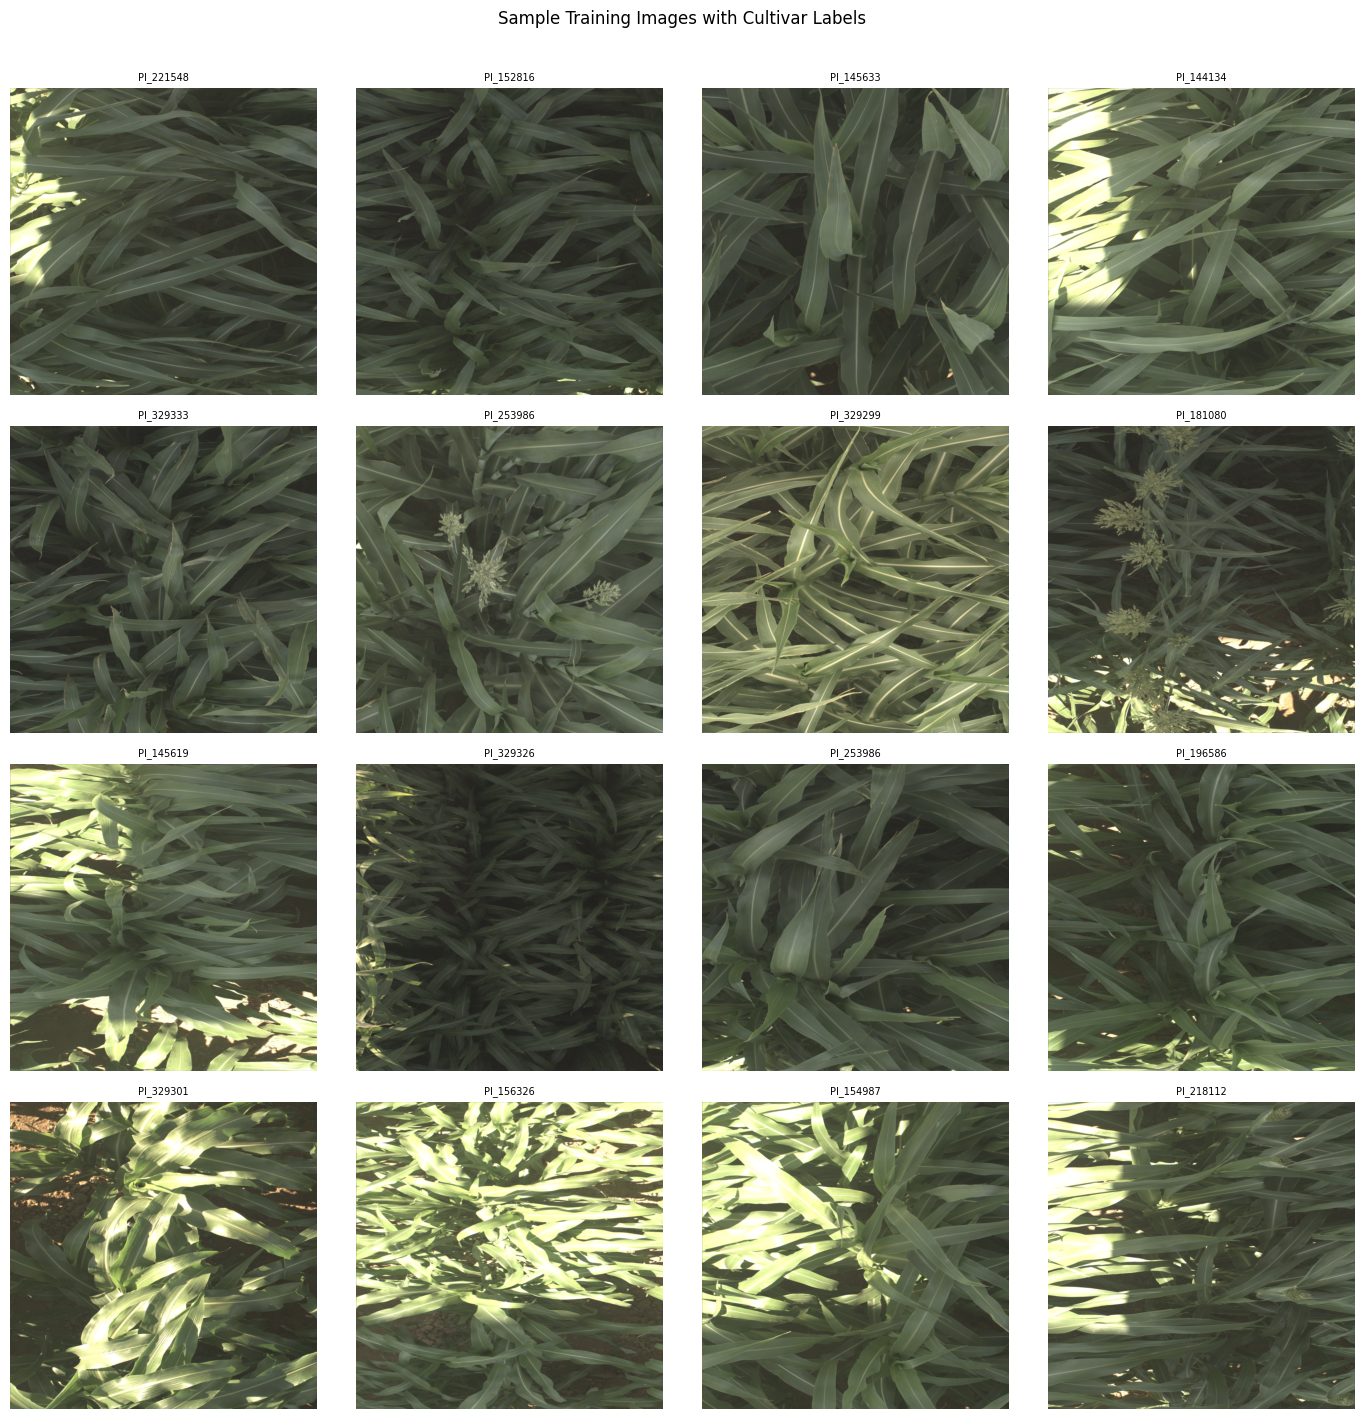

In [16]:
# Build a lookup: filename → cultivar
label_map = dict(zip(df[IMAGE_COL], df[CULTIVAR_COL]))

# Sample 16 images that exist on disk and have a cultivar label
valid_files = [p for p in image_files if p.name in label_map and pd.notna(label_map[p.name])]
grid_sample = random.sample(valid_files, min(16, len(valid_files)))

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for ax, path in zip(axes.flat, grid_sample):
    ax.imshow(Image.open(path))
    ax.set_title(label_map[path.name], fontsize=7)
    ax.axis("off")

# Hide any unused subplots
for ax in axes.flat[len(grid_sample):]:
    ax.axis("off")

plt.suptitle("Sample Training Images with Cultivar Labels", fontsize=12, y=1.01)
plt.tight_layout()

out_path = RESULTS_DIR / "sample_training_images.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved: {out_path}")
plt.show()

## Section 12 — Metadata inspection

In [17]:
# ── germplasm.csv ────────────────────────────────────────────────────────────
germ = pd.read_csv(GERMPLASM_CSV)
print("germplasm.csv")
print(f"  Shape   : {germ.shape}")
print(f"  Columns : {germ.columns.tolist()}")
print(f"  Missing :\n{germ.isnull().sum().to_string()}")
print()
germ.head()

germplasm.csv
  Shape   : (352, 4)
  Columns : ['germplasmName', 'germplasmPUI', 'season_4', 'season_6']
  Missing :
germplasmName     0
germplasmPUI     62
season_4          1
season_6         27



,germplasmName,germplasmPUI,season_4,season_6
0,PI221548,https://purl.org/germplasm/id/dd1e5189-e9b1-4f...,True,True
1,PI576401,https://purl.org/germplasm/id/6bf2d2e7-8806-47...,True,True
2,PI570388,https://purl.org/germplasm/id/98b6133c-76f9-46...,True,True
3,PI152651,https://purl.org/germplasm/id/1fa3d272-de99-48...,True,True
4,PI329351,https://purl.org/germplasm/id/25c07ed7-ae91-44...,True,True


In [18]:
# ── season_6_aboveground_fresh_biomass_manual.csv ────────────────────────────
# NOTE: This file contains manual aboveground fresh biomass measurements
# from the MAC Field Scanner Season 6 experiment.
# It is NOT a label file for cultivar classification.
# Its relationship to train_cultivar_mapping.csv requires further investigation.
bio = pd.read_csv(BIOMASS_CSV)
print("season_6_aboveground_fresh_biomass_manual.csv")
print(f"  Shape   : {bio.shape}")
print(f"  Columns : {bio.columns.tolist()}")
print(f"  Missing :\n{bio.isnull().sum().to_string()}")
print()
bio.head()

season_6_aboveground_fresh_biomass_manual.csv
  Shape   : (711, 12)
  Columns : ['plot', 'scientificname', 'genotype', 'treatment', 'date', 'trait', 'method', 'mean', 'checked', 'author', 'season', 'method_type']
  Missing :
plot              0
scientificname    0
genotype          0
treatment         0
date              0
trait             0
method            0
mean              0
checked           0
author            0
season            0
method_type       0



,plot,scientificname,genotype,treatment,date,trait,method,mean,checked,author,season,method_type
0,MAC Field Scanner Season 6 Range 21 Column 2,Sorghum bicolor,PI569457,MAC Season 6: Sorghum,2018-08-01,aboveground_fresh_biomass,Aboveground fresh biomass at harvest,19100,0,"Newcomb, Maria",Season 6,manual
1,MAC Field Scanner Season 6 Range 21 Column 4,Sorghum bicolor,PI535785,MAC Season 6: Sorghum,2018-08-01,aboveground_fresh_biomass,Aboveground fresh biomass at harvest,45900,0,"Newcomb, Maria",Season 6,manual
2,MAC Field Scanner Season 6 Range 30 Column 4,Sorghum bicolor,PI570106,MAC Season 6: Sorghum,2018-08-01,aboveground_fresh_biomass,Aboveground fresh biomass at harvest,41300,0,"Newcomb, Maria",Season 6,manual
3,MAC Field Scanner Season 6 Range 2 Column 3,Sorghum bicolor,SP1516,MAC Season 6: Sorghum,2018-07-31,aboveground_fresh_biomass,Aboveground fresh biomass at harvest,51900,0,"Newcomb, Maria",Season 6,manual
4,MAC Field Scanner Season 6 Range 2 Column 7,Sorghum bicolor,SP1516,MAC Season 6: Sorghum,2018-07-31,aboveground_fresh_biomass,Aboveground fresh biomass at harvest,50200,0,"Newcomb, Maria",Season 6,manual


In [19]:
# Check overlap between germplasm names and cultivar labels in the mapping CSV
mapping_cultivars  = set(df[CULTIVAR_COL].dropna().unique())
germplasm_names    = set(germ["germplasmName"].dropna().unique())
biomass_genotypes  = set(bio["genotype"].dropna().unique())

overlap_germ   = mapping_cultivars & germplasm_names
overlap_bio    = mapping_cultivars & biomass_genotypes

print(f"Cultivars in mapping CSV                    : {len(mapping_cultivars)}")
print(f"Entries in germplasm.csv                    : {len(germplasm_names)}")
print(f"Overlap (mapping ∩ germplasm)               : {len(overlap_germ)}")
print()
print(f"Genotypes in biomass CSV                    : {len(biomass_genotypes)}")
print(f"Overlap (mapping cultivars ∩ biomass geno.) : {len(overlap_bio)}")
print()
print("Note: The relationship between these files requires further investigation.")
print("The biomass CSV is NOT used for cultivar classification.")

Cultivars in mapping CSV                    : 100
Entries in germplasm.csv                    : 352
Overlap (mapping ∩ germplasm)               : 0

Genotypes in biomass CSV                    : 326
Overlap (mapping cultivars ∩ biomass geno.) : 0

Note: The relationship between these files requires further investigation.
The biomass CSV is NOT used for cultivar classification.


## Section 13 — Dataset quality report

In [20]:
report = f"""
Dataset Exploration Summary — August 14, 2026
==============================================

Dataset layout
--------------
  Images and CSVs are flat inside Dataset/ (no subfolder).
  There is no genotype.csv; the third file is season_6_aboveground_fresh_biomass_manual.csv.

Training images
---------------
  PNG images on disk          : {len(image_files)}
  Rows in mapping CSV         : {total_rows}
  Unique mapped image names   : {unique_images}
  Unique cultivar labels      : {unique_cultivars}

Class distribution
------------------
  Min images / class          : {counts_per_class.min()}
  Max images / class          : {counts_per_class.max()}
  Mean images / class         : {counts_per_class.mean():.1f}
  Median images / class       : {counts_per_class.median():.1f}

Mapping quality
---------------
  Missing image filenames     : {missing_image}
  Missing cultivar labels     : {missing_cultivar}
  Duplicate rows              : {dup_rows}
  Duplicate image filenames   : {dup_images}
  Mapped files missing on disk: {len(missing_on_disk)}
  Files on disk not in CSV    : {len(unmapped_on_disk)}

Image properties (sample of {SAMPLE_SIZE})
-------------------------------------------
  Width  — min: {min(widths)}, max: {max(widths)}, mean: {sum(widths)/len(widths):.0f}
  Height — min: {min(heights)}, max: {max(heights)}, mean: {sum(heights)/len(heights):.0f}
  Color modes                 : {set(modes)}
  Formats                     : {set(formats)}
  Unique (W, H) combinations  : {len(unique_sizes)}

Metadata files
--------------
  germplasm.csv               : {germ.shape[0]} rows, {germ.shape[1]} columns
  biomass CSV                 : {bio.shape[0]} rows, {bio.shape[1]} columns
  Cultivar ∩ germplasm overlap: {len(overlap_germ)}
  Cultivar ∩ biomass overlap  : {len(overlap_bio)}

Known issues
------------
  - One row in train_cultivar_mapping.csv has filename '.DS_Store' with empty cultivar.
  - Biomass CSV relationship to image mapping requires further investigation.
  - Image dimensions may not be uniform (check unique_sizes above).
"""

print(report)


Dataset Exploration Summary — August 14, 2026

Dataset layout
--------------
  Images and CSVs are flat inside Dataset/ (no subfolder).
  There is no genotype.csv; the third file is season_6_aboveground_fresh_biomass_manual.csv.

Training images
---------------
  PNG images on disk          : 5000
  Rows in mapping CSV         : 22194
  Unique mapped image names   : 22194
  Unique cultivar labels      : 100

Class distribution
------------------
  Min images / class          : 134
  Max images / class          : 298
  Mean images / class         : 221.9
  Median images / class       : 235.5

Mapping quality
---------------
  Missing image filenames     : 0
  Missing cultivar labels     : 1
  Duplicate rows              : 0
  Duplicate image filenames   : 0
  Mapped files missing on disk: 17194
  Files on disk not in CSV    : 0

Image properties (sample of 100)
-------------------------------------------
  Width  — min: 1024, max: 1024, mean: 1024
  Height — min: 1024, max: 1024, mean:

## Section 14 — Save dataset summary

In [21]:
summary_dict = {
    "exploration_date": "2026-08-14",
    "dataset_layout": "flat — images and CSVs directly in Dataset/",
    "png_images_on_disk": len(image_files),
    "mapping_csv_rows": total_rows,
    "unique_mapped_images": unique_images,
    "unique_cultivars": unique_cultivars,
    "min_images_per_class": int(counts_per_class.min()),
    "max_images_per_class": int(counts_per_class.max()),
    "mean_images_per_class": round(float(counts_per_class.mean()), 1),
    "median_images_per_class": float(counts_per_class.median()),
    "missing_image_filenames": int(missing_image),
    "missing_cultivar_labels": int(missing_cultivar),
    "duplicate_rows": int(dup_rows),
    "duplicate_image_filenames": int(dup_images),
    "mapped_files_missing_on_disk": len(missing_on_disk),
    "files_on_disk_not_in_csv": len(unmapped_on_disk),
    "image_sample_size": SAMPLE_SIZE,
    "width_min": min(widths),
    "width_max": max(widths),
    "width_mean": round(sum(widths) / len(widths), 1),
    "height_min": min(heights),
    "height_max": max(heights),
    "height_mean": round(sum(heights) / len(heights), 1),
    "unique_wh_combinations": len(unique_sizes),
    "color_modes": list(set(modes)),
    "image_formats": list(set(formats)),
    "germplasm_rows": int(germ.shape[0]),
    "biomass_rows": int(bio.shape[0]),
    "cultivar_germplasm_overlap": len(overlap_germ),
    "cultivar_biomass_overlap": len(overlap_bio),
    "known_issues": [
        "One row has filename '.DS_Store' with empty cultivar label",
        "No genotype.csv — third file is season_6_aboveground_fresh_biomass_manual.csv",
        "Biomass CSV relationship to image mapping requires further investigation"
    ]
}

summary_path = RESULTS_DIR / "dataset_summary.json"
summary_path.write_text(json.dumps(summary_dict, indent=2))
print(f"Summary saved to: {summary_path}")

Summary saved to: ..\results\dataset_summary.json
